# Datos no estructurados
### Texto e imágenes extraídos desde una API pública 

**Objetivos**
1. Explicar qué es un dato **no estructurado** y en qué se diferencia de los estructurados y semiestructurados.
2. **Comunicarse con una API** pública y extraer texto e imágenes reales.
3. Aprender a **convertir** datos no estructurados en **números y tablas** que se puedan analizar.
4. Practicar con **6 ejercicios**

**API usada:** la API de **Wikipedia** (MediaWiki Action API) — pública, **sin clave ni registro**.


##  Agenda

| # | Sección |
|---|---|
| 1 | ¿Qué son los datos no estructurados? |
| 2 | El flujo de trabajo: de dato crudo a conocimiento |
| 3 | Comunicación con una API (conceptos) |
| 4 | Extracción de texto e imágenes desde Wikipedia |
| 5 | Análisis de **texto**: limpieza, frecuencias, TF-IDF, similitud |
| 6 | Análisis de **imágenes**: píxeles, características, huella visual |
| 7 | Otros no estructurados (audio, video, PDF) y tabla final |
| 8 | Buenas prácticas al consumir APIs |
| 9 | Ejercicios (6) |

# 1 · ¿Qué son los datos no estructurados?

Son datos **sin un esquema fijo** de filas y columnas: su contenido tiene significado para una persona, pero no está organizado para que un programa lo consulte directamente.

| Tipo de dato | Estructura | Ejemplo | ¿Se consulta con SQL? |
|---|---|---|---|
| **Estructurado** | Esquema fijo (tablas) | hoja de Excel de ventas | ✅ |
| **Semiestructurado** | Etiquetas, sin forma fija | JSON de una API | ⚠️ parcialmente |
| **No estructurado** | Sin esquema | texto, imagen, audio, video | ❌ |

**Ejemplos cotidianos:** correos, reseñas, publicaciones en redes, fotos, grabaciones de voz, videos, PDF escaneados, registros (*logs*) de texto libre.

> 💡 Un dato no estructurado **no es un dato sin valor**: contiene muchísima información, pero hay que **extraer características** antes de analizarlo.

**Pista conceptual para este notebook:** la API de Wikipedia responde en **JSON** (semiestructurado), pero dentro de ese JSON viaja **texto libre** (no estructurado) y enlaces a **imágenes**.

# 2 · El flujo de trabajo

```
 1. OBTENER      →  2. PREPROCESAR   →  3. REPRESENTAR      →  4. ANALIZAR      →  5. COMUNICAR
 (API, archivos)    (limpiar,           (convertir en          (frecuencias,       (gráficos,
                     normalizar)         números/vectores)      similitud, modelos)  tablas)
```

| Paso | En texto | En imágenes |
|---|---|---|
| Obtener | API → `extract` | API → URL → descarga de bytes |
| Preprocesar | minúsculas, quitar signos, *stopwords* | convertir a RGB, redimensionar |
| Representar | bolsa de palabras, TF-IDF | matriz de píxeles, histogramas, huella |
| Analizar | palabras clave, similitud coseno | brillo, contraste, color dominante |

# 3 · Comunicarse con una API

Una **API** (*Application Programming Interface*) es una puerta que un servicio abre para que **otros programas** le pidan datos.
Una **API REST** funciona sobre HTTP: tu programa envía una **petición** y el servidor devuelve una **respuesta**.

```
  Tu notebook  ── GET https://es.wikipedia.org/w/api.php?action=query&list=search&srsearch=Ecuador ──▶  Servidor
               ◀── 200 OK  +  JSON { "query": { "search": [ {...}, {...} ] } } ────────────────────────
```

| Concepto | Significado | En este notebook |
|---|---|---|
| **Endpoint** | Dirección a la que se consulta | `https://es.wikipedia.org/w/api.php` |
| **Parámetros** | Qué se pide (van tras el `?`) | `action`, `list`, `srsearch`, `titles`… |
| **Método** | Tipo de petición | `GET` (solo leer) |
| **Código de estado** | Resultado | `200` correcto · `404` no existe · `429` demasiadas peticiones |
| **Cabecera `User-Agent`** | Quién consulta | Wikipedia pide identificarse |
| **Autenticación** | Clave/token | ❌ **No se necesita** |

### Las 3 consultas que usaremos

| Para qué | Parámetros clave |
|---|---|
| **Buscar** artículos | `list=search` · `srsearch=<tema>` |
| **Texto** completo (plano) | `prop=extracts` · `explaintext=1` · `titles=<título>` |
| **Imagen** principal | `prop=pageimages` · `piprop=thumbnail` · `pithumbsize=400` |

> 📜 El texto de Wikipedia se publica bajo licencia **CC BY-SA**.

# 4 · Extracción desde Wikipedia

Primero la configuración. **Edita** `TEMAS` si quieres analizar otros artículos, y `USER_AGENT` para poner tu correo (buena práctica).

In [2]:
# %pip install -q requests pillow pandas numpy matplotlib

import os, re, io, json, math, time, html, hashlib, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})

# ---------------- Configuración ----------------
IDIOMA = "es"                                             # "es" español · "en" inglés
API_URL = os.environ.get("WIKI_API_URL", f"https://{IDIOMA}.wikipedia.org/w/api.php")   # (avanzado) permite apuntar a otro servidor
USER_AGENT = "NotebookCienciaDeDatos/1.0 (uso educativo; cambia esto por tu correo)"
HEADERS = {"User-Agent": USER_AGENT}
TEMAS = ["Inteligencia artificial", "Aprendizaje automático", "Base de datos",
         "Volcán Cotopaxi", "Ecuador", "Cambio climático", "Machine Learning"]
CACHE_DIR = "cache_wikipedia"                             # guarda respuestas para no repetir peticiones
PAUSA_S = 0.3                                             # pausa cortés entre peticiones
print("pandas", pd.__version__, "· endpoint:", API_URL)

pandas 3.0.6 · endpoint: https://es.wikipedia.org/w/api.php


### 4.1 Nuestro cliente de la API

La función `consultar_wikipedia` hace la petición, revisa errores, **reintenta** si hace falta y guarda la respuesta en una carpeta de **caché** (así no se repite la misma petición dos veces).

In [3]:
def consultar_wikipedia(params, usar_cache=True):
    p = {"format": "json", "formatversion": "2", **params}
    clave = hashlib.sha1((API_URL + json.dumps(p, sort_keys=True)).encode()).hexdigest()[:16]
    ruta = os.path.join(CACHE_DIR, clave + ".json")
    if usar_cache and os.path.exists(ruta):
        with open(ruta, encoding="utf-8") as f:
            return json.load(f)

    datos = None
    for intento in range(3):
        try:
            r = requests.get(API_URL, params=p, headers=HEADERS, timeout=20)
            if r.status_code == 429:                       # demasiadas peticiones: esperar y reintentar
                time.sleep(2 * (intento + 1))
                continue
            r.raise_for_status()
            datos = r.json()
            break
        except requests.RequestException:
            if intento == 2:
                raise
            time.sleep(1.5)
    if datos is None:
        raise RuntimeError("La API no respondió correctamente")
    if "error" in datos:
        raise RuntimeError(datos["error"].get("info", "error de la API"))

    os.makedirs(CACHE_DIR, exist_ok=True)
    with open(ruta, "w", encoding="utf-8") as f:
        json.dump(datos, f, ensure_ascii=False)
    time.sleep(PAUSA_S)
    return datos


def buscar_articulos(tema, n=5):
    d = consultar_wikipedia({"action": "query", "list": "search", "srsearch": tema, "srlimit": n})
    return d["query"]["search"]


def obtener_texto(titulo):
    d = consultar_wikipedia({"action": "query", "prop": "extracts", "explaintext": 1,
                             "exsectionformat": "plain", "redirects": 1, "titles": titulo})
    return d["query"]["pages"][0].get("extract", "")


def obtener_url_imagen(titulo, ancho=400):
    d = consultar_wikipedia({"action": "query", "prop": "pageimages", "piprop": "thumbnail",
                             "pithumbsize": ancho, "redirects": 1, "titles": titulo})
    return d["query"]["pages"][0].get("thumbnail", {}).get("source")


def descargar_imagen(url):
    ruta = os.path.join(CACHE_DIR, "img_" + hashlib.sha1(url.encode()).hexdigest()[:16] + ".bin")
    if os.path.exists(ruta):
        with open(ruta, "rb") as f:
            datos = f.read()
    else:
        r = requests.get(url, headers=HEADERS, timeout=30)
        r.raise_for_status()
        datos = r.content
        os.makedirs(CACHE_DIR, exist_ok=True)
        with open(ruta, "wb") as f:
            f.write(datos)
        time.sleep(PAUSA_S)
    return Image.open(io.BytesIO(datos)).convert("RGB")


# ¿Hay conexión con la API?
try:
    consultar_wikipedia({"action": "query", "list": "search", "srsearch": "Ecuador", "srlimit": 1}, usar_cache=False)
    MODO_OFFLINE = False
    print("✅ Conexión con la API de Wikipedia: OK")
except Exception as e:
    MODO_OFFLINE = True
    print(f"⚠️ Sin conexión a la API ({type(e).__name__}). Se usarán datos de respaldo incluidos en el notebook.")

✅ Conexión con la API de Wikipedia: OK


### 4.2 Primera consulta: buscar y mirar la respuesta cruda

Observa: la API devuelve **JSON** (semiestructurado). Dentro hay una lista de resultados con título, número de palabras y un fragmento (*snippet*) con **etiquetas HTML** que habrá que limpiar.

In [4]:
if not MODO_OFFLINE:
    crudo = consultar_wikipedia({"action": "query", "list": "search", "srsearch": "Volcán Cotopaxi", "srlimit": 3})
else:
    crudo = {"query": {"search": [{"ns": 0, "title": "Cotopaxi", "pageid": 0, "wordcount": 3000,
             "snippet": 'El <span class="searchmatch">Cotopaxi</span> es un volcán activo de los Andes (ejemplo ilustrativo)'}]}}
    print("(Respuesta ilustrativa: no hay conexión)\n")

print(json.dumps(crudo, indent=2, ensure_ascii=False)[:1400])

resultados = pd.DataFrame(crudo["query"]["search"])
resultados["snippet_limpio"] = resultados["snippet"].apply(lambda s: html.unescape(re.sub(r"<[^>]+>", "", s)))
display(resultados[[c for c in ["title", "wordcount", "snippet_limpio"] if c in resultados.columns]])

{
  "batchcomplete": true,
  "continue": {
    "sroffset": 3,
    "continue": "-||"
  },
  "query": {
    "searchinfo": {
      "totalhits": 159
    },
    "search": [
      {
        "ns": 0,
        "title": "Volcán Cotopaxi",
        "pageid": 95905,
        "size": 16205,
        "wordcount": 1554,
        "snippet": "El <span class=\"searchmatch\">volcán</span> <span class=\"searchmatch\">Cotopaxi</span> (pronunciado [ko.toˈpak.si]) es un estratovolcán activo, situado en el centro-norte de Ecuador, en la provincia de <span class=\"searchmatch\">Cotopaxi</span>. Perteneciente",
        "timestamp": "2026-06-04T10:16:05Z"
      },
      {
        "ns": 0,
        "title": "Parque nacional Cotopaxi",
        "pageid": 1248777,
        "size": 12872,
        "wordcount": 1346,
        "snippet": "provincia <span class=\"searchmatch\">cotopaxi</span> se encuentra el nevado <span class=\"searchmatch\">Volcán</span> <span class=\"searchmatch\">Cotopaxi</span>. Fue el primer parque nacion

,title,wordcount,snippet_limpio
0,Volcán Cotopaxi,1554,"El volcán Cotopaxi (pronunciado [ko.toˈpak.si]) es un estratovolcán activo, ..."
1,Parque nacional Cotopaxi,1346,provincia cotopaxi se encuentra el nevado Volcán Cotopaxi. Fue el primer par...
2,Provincia de Cotopaxi,3511,la provincia de Cotopaxi. La provincia toma el nombre del volcán más grande ...


### 4.3 Construir el corpus

Para cada tema: **buscamos** el artículo más relevante, **descargamos su texto** y obtenemos la **URL de su imagen principal**.
Si algo falla (sin Internet, artículo muy corto), se usa un texto de respaldo y se avisa en la columna `origen`.

In [5]:
CORPUS_RESPALDO = {
 "Inteligencia artificial": "La inteligencia artificial es la disciplina que estudia cómo lograr que las máquinas realicen tareas que normalmente requieren inteligencia humana, como reconocer imágenes, comprender el lenguaje o tomar decisiones. En 1956, durante la conferencia de Dartmouth, John McCarthy propuso el nombre del campo junto a otros investigadores como Marvin Minsky. Desde entonces la inteligencia artificial ha vivido épocas de entusiasmo y periodos de estancamiento conocidos como inviernos. En 2012 las redes neuronales profundas lograron avances notables en visión por computador, y en 2022 los modelos de lenguaje de gran tamaño llegaron al público general. Hoy la inteligencia artificial se aplica en medicina, educación, finanzas y transporte, aunque plantea retos sobre sesgos, privacidad y responsabilidad. Los datos, tanto estructurados como no estructurados, son el combustible de estos sistemas.",
 "Aprendizaje automático": "El aprendizaje automático es una rama de la inteligencia artificial en la que los algoritmos aprenden patrones a partir de datos en lugar de seguir reglas escritas a mano. Existen tres grandes enfoques: el aprendizaje supervisado, que usa ejemplos con respuesta conocida; el aprendizaje no supervisado, que descubre estructuras ocultas; y el aprendizaje por refuerzo, que mejora mediante recompensas. En 1959 Arthur Samuel popularizó el término al describir un programa que aprendía a jugar a las damas. Para entrenar un modelo se divide el conjunto de datos en entrenamiento y prueba, y se evalúa con métricas como la exactitud. Los textos y las imágenes deben transformarse antes en vectores numéricos para que los algoritmos puedan procesarlos. Un modelo con exceso de ajuste memoriza los datos de entrenamiento y falla con datos nuevos.",
 "Base de datos": "Una base de datos es un conjunto organizado de información almacenada de forma que pueda consultarse, actualizarse y administrarse con facilidad. El modelo relacional, propuesto por Edgar Codd en 1970, organiza los datos en tablas formadas por filas y columnas, y relaciona las tablas mediante claves primarias y claves foráneas. El lenguaje SQL permite consultar y modificar los datos de estas tablas. A partir de 2009 se popularizaron las bases de datos no relacionales, como las de documentos y las de grafos, pensadas para datos semiestructurados y grandes volúmenes. Un sistema gestor de bases de datos garantiza la integridad, la seguridad y la concurrencia de las transacciones. PostgreSQL y MySQL son ejemplos de sistemas gestores muy utilizados en aplicaciones web.",
 "Volcán Cotopaxi": "El Cotopaxi es un volcán activo de los Andes ubicado en Ecuador, en las provincias de Cotopaxi, Napo y Pichincha. Con cerca de 5897 metros de altura es uno de los volcanes activos más altos del mundo y su cono cubierto de nieve es muy reconocido. Sus erupciones históricas, como las de 1744, 1768 y 1877, produjeron flujos de lodo que descendieron por los valles cercanos. En 2015 el volcán volvió a mostrar actividad y las autoridades vigilaron las cenizas y los lahares. El Parque Nacional Cotopaxi protege el páramo, los lagos y la fauna andina, y recibe a miles de turistas y escaladores cada año. Los habitantes de Latacunga y de los valles vecinos conocen los planes de evacuación ante una posible erupción.",
 "Ecuador": "Ecuador es un país de América del Sur atravesado por la línea ecuatorial, de la cual toma su nombre. Su capital es Quito y su ciudad más poblada es Guayaquil. El territorio se divide en cuatro regiones: la Costa, la Sierra, la Amazonía y las islas Galápagos, famosas por la biodiversidad que inspiró a Charles Darwin en 1835. Ecuador se independizó de España en 1822 tras la batalla de Pichincha. La economía depende de la exportación de petróleo, banano, camarón y flores, y desde el año 2000 utiliza el dólar estadounidense como moneda. La Sierra concentra volcanes como el Cotopaxi y el Chimborazo, mientras que la Amazonía conserva extensas selvas tropicales.",
 "Cambio climático": "El cambio climático es la variación a largo plazo de las temperaturas y de los patrones del clima en el planeta. Desde la Revolución Industrial del siglo XIX, la quema de carbón, petróleo y gas ha aumentado la concentración de dióxido de carbono en la atmósfera, lo que intensifica el efecto invernadero. Los científicos miden estos cambios con series de temperatura, imágenes de satélite y registros de glaciares. En 1997 se firmó el Protocolo de Kioto y en 2015 el Acuerdo de París, que busca limitar el calentamiento global muy por debajo de 2 grados. Entre las consecuencias se encuentran el derretimiento de glaciares, el aumento del nivel del mar, las sequías y las lluvias extremas. Los países andinos, como Ecuador, observan el retroceso acelerado de sus glaciares."
}

In [6]:
corpus = {}
for tema in TEMAS:
    try:
        if MODO_OFFLINE:
            raise ConnectionError("modo sin conexión")
        titulo = buscar_articulos(tema, 3)[0]["title"]
        texto = obtener_texto(titulo)
        if len(texto) < 400:
            raise ValueError("artículo demasiado corto")
        corpus[tema] = {"titulo": titulo, "texto": texto, "url_imagen": obtener_url_imagen(titulo), "origen": "API Wikipedia"}
    except Exception as e:
        corpus[tema] = {"titulo": tema, "texto": CORPUS_RESPALDO.get(tema, tema), "url_imagen": None,
                        "origen": "respaldo local"}

resumen_corpus = pd.DataFrame.from_dict({t: {"título": d["titulo"], "caracteres": len(d["texto"]),
                                              "tiene_imagen": d["url_imagen"] is not None, "origen": d["origen"]}
                                          for t, d in corpus.items()}, orient="index")
display(resumen_corpus)

tema_demo = TEMAS[3]
print(f"\nPrimeros 500 caracteres del texto de «{corpus[tema_demo]['titulo']}»:\n")
print(corpus[tema_demo]["texto"][:500], "...")

,título,caracteres,tiene_imagen,origen
Inteligencia artificial,Inteligencia artificial,86163,True,API Wikipedia
Aprendizaje automático,Aprendizaje automático,19021,True,API Wikipedia
Base de datos,Base de datos,27809,True,API Wikipedia
Volcán Cotopaxi,Volcán Cotopaxi,6975,True,API Wikipedia
Ecuador,Ecuador,120060,True,API Wikipedia
Cambio climático,Cambio climático,64410,True,API Wikipedia
Machine Learning,Aprendizaje automático,19021,True,API Wikipedia



Primeros 500 caracteres del texto de «Volcán Cotopaxi»:

El volcán Cotopaxi (pronunciado [ko.toˈpak.si]) es un estratovolcán activo, situado en el centro-norte de Ecuador, en la provincia de Cotopaxi. Perteneciente a la cordillera de los Andes, específicamente a los Andes septentrionales, cuenta con una altitud de 5897 m s. n. m.; por lo que es la segunda montaña más alta del Ecuador y de los Andes septentrionales, sólo superado por el volcán Chimborazo.
Su última gran erupción se remonta al 26 de junio de 1877;​ no obstante, desde 2015 se encuentra e ...


# 5 · Análisis de texto

**Meta:** convertir cada documento en **números** para poder compararlos.

| Paso | Técnica | Resultado |
|---|---|---|
| 5.1 | Exploración básica | tamaño de cada texto |
| 5.2 | Preprocesamiento | lista de *tokens* limpios |
| 5.3 | Frecuencias y *n-gramas* | palabras y frases típicas |
| 5.4 | Bolsa de palabras y **TF-IDF** | matriz documento × término |
| 5.5 | **Similitud coseno** | qué textos se parecen |
| 5.6 | Extracción con expresiones regulares | variables estructuradas |

## 5.1 Exploración básica

,caracteres,palabras,oraciones,párrafos
Inteligencia artificial,86163,13142,368,299
Aprendizaje automático,19021,2864,110,145
Base de datos,27809,4310,172,163
Volcán Cotopaxi,6975,1138,34,39
Ecuador,120060,19189,487,307
Cambio climático,64410,9920,272,171
Machine Learning,19021,2864,110,145


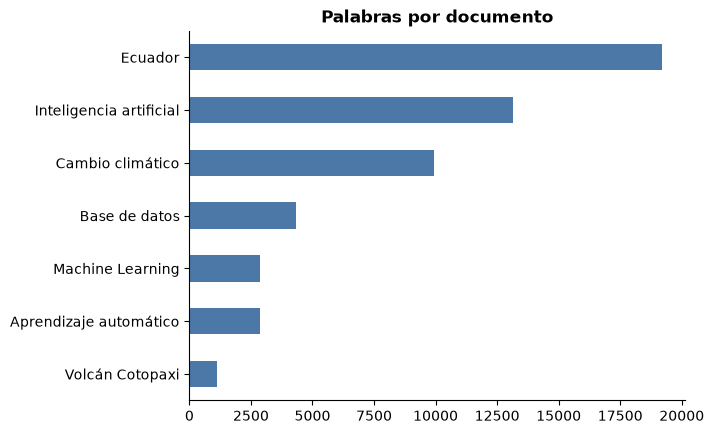

In [7]:
def contar_oraciones(t):
    return len([s for s in re.split(r"[.!?]+\s", t) if len(s.split()) > 2])


exploracion = pd.DataFrame.from_dict({
    t: {"caracteres": len(d["texto"]), "palabras": len(d["texto"].split()),
        "oraciones": contar_oraciones(d["texto"]), "párrafos": len([p for p in d["texto"].split("\n") if p.strip()])}
    for t, d in corpus.items()}, orient="index")
display(exploracion)
exploracion["palabras"].sort_values().plot.barh(color="#4C78A8", title="Palabras por documento")
plt.show()

## 5.2 Preprocesamiento

Un computador ve `Datos`, `datos` y `datos,` como cadenas **distintas**. Hay que **normalizar**:

1. pasar a minúsculas,
2. quitar URL, signos y números,
3. separar en palabras (**tokenizar**),
4. descartar palabras muy cortas y las ***stopwords*** (palabras vacías: *el, de, que…*).

In [8]:
STOPWORDS = set("""a al algo algunas algunos ante antes aquí así aún además allí bajo cada como cómo con contra cual cuales cuando de del desde donde durante e el él ella ellas ellos en entre era eran eres es esa esas ese eso esos esta está estaba estaban están estar este esto estos fue fueron ha había habían han hasta hay he hace hacia la las le les lo los más me mi mis mucho muy nada ni no nos nosotros o os otra otras otro otros para pero poco por porque puede pueden qué que quien quienes se sea sean según ser si sí sido siendo sin sobre solo son soy su sus también tan tanto te tiene tienen todo todos tras tu tus un una uno unos vez veces y ya yo entonces IA machine""".split())
print("Stopwords definidas:", len(STOPWORDS))

Stopwords definidas: 136


In [9]:
def limpiar_texto(texto, min_len=3, quitar_stop=True):
    t = texto.lower()
    t = re.sub(r"https?://\S+", " ", t)
    tokens = re.findall(r"[a-záéíóúüñ]+", t)
    return [w for w in tokens if len(w) >= min_len and (not quitar_stop or w not in STOPWORDS)]


frase = "¡Los volcanes de Ecuador, como el Cotopaxi, son 100% impresionantes! Más info: https://ejemplo.com"
print("ORIGINAL :", frase)
print("TOKENS   :", limpiar_texto(frase))

tokens_por_tema = {t: limpiar_texto(d["texto"]) for t, d in corpus.items()}
pd.DataFrame({"tokens_limpios": {t: len(v) for t, v in tokens_por_tema.items()},
              "palabras_unicas": {t: len(set(v)) for t, v in tokens_por_tema.items()}})

ORIGINAL : ¡Los volcanes de Ecuador, como el Cotopaxi, son 100% impresionantes! Más info: https://ejemplo.com
TOKENS   : ['volcanes', 'ecuador', 'cotopaxi', 'impresionantes', 'info']


,tokens_limpios,palabras_unicas
Inteligencia artificial,6848,3109
Aprendizaje automático,1506,838
Base de datos,2317,1084
Volcán Cotopaxi,582,408
Ecuador,9834,4226
Cambio climático,5108,2312
Machine Learning,1506,838


## 5.3 Frecuencias y n-gramas
Las palabras más frecuentes (tras limpiar) revelan **de qué trata** cada texto. Un **bigrama** es un par de palabras seguidas.

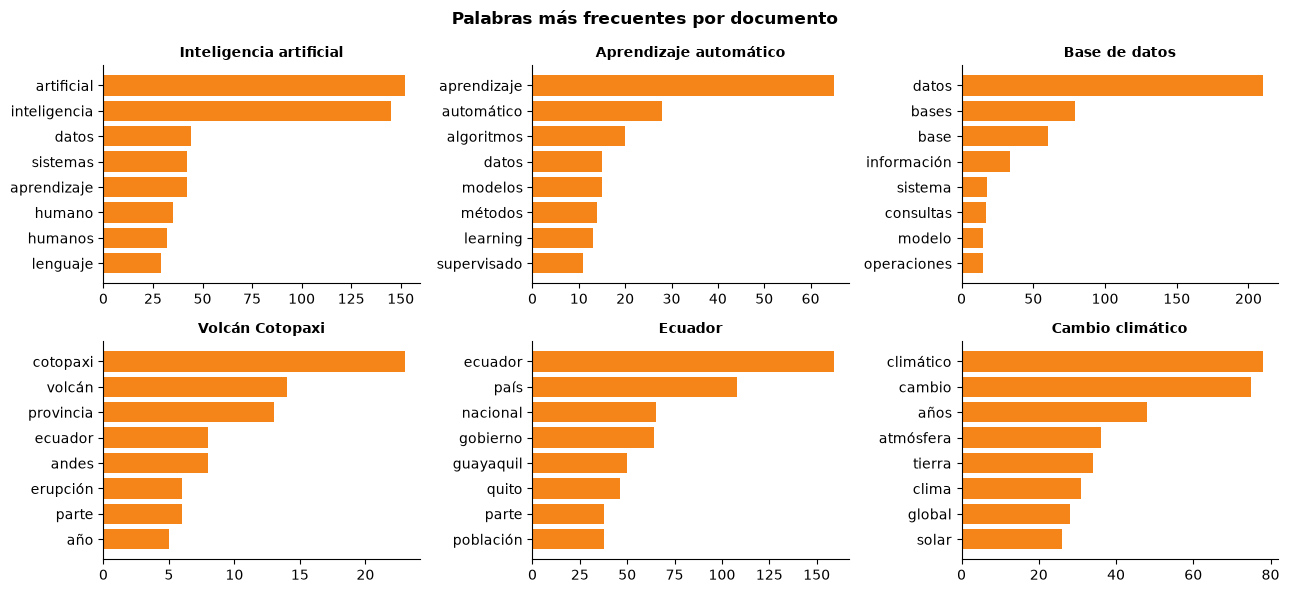

,bigrama,frecuencia
0,inteligencia artificial,139
1,bases datos,79
2,cambio climático,66
3,aprendizaje automático,65
4,base datos,60
5,aprendizaje supervisado,23
6,artificial intelligence,19
7,algoritmos aprendizaje,18
8,efecto invernadero,16
9,aprendizaje profundo,15


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, (tema, toks) in zip(axes.ravel(), tokens_por_tema.items()):
    top = Counter(toks).most_common(8)[::-1]
    ax.barh([p for p, _ in top], [n for _, n in top], color="#F58518")
    ax.set_title(tema, fontsize=10)
plt.suptitle("Palabras más frecuentes por documento", fontweight="bold")
plt.tight_layout(); plt.show()

bigramas = Counter()
for toks in tokens_por_tema.values():
    bigramas.update(zip(toks, toks[1:]))
display(pd.DataFrame([(" ".join(b), n) for b, n in bigramas.most_common(10)], columns=["bigrama", "frecuencia"]))

## 5.4 Bolsa de palabras y TF-IDF

**Bolsa de palabras:** cada documento = vector con el **conteo** de cada palabra del vocabulario (se ignora el orden).

**TF-IDF** corrige el problema de que las palabras comunes dominan:

- **TF** (frecuencia del término): qué tanto aparece la palabra **en este** documento.
- **IDF** (frecuencia inversa): qué tan **rara** es la palabra en el conjunto de documentos.
- **TF-IDF = TF × IDF** → destaca palabras **frecuentes aquí y raras en los demás**, es decir, las más *distintivas*.

In [11]:
temas = list(tokens_por_tema)
conteo_total = Counter(w for toks in tokens_por_tema.values() for w in toks)
vocab = sorted(w for w, n in conteo_total.items() if n >= 3)          # vocabulario: palabras con al menos 3 apariciones
indice = {w: i for i, w in enumerate(vocab)}

bow = np.zeros((len(temas), len(vocab)))
for i, t in enumerate(temas):
    for w, n in Counter(tokens_por_tema[t]).items():
        if w in indice:
            bow[i, indice[w]] = n

tf = bow / bow.sum(axis=1, keepdims=True)
df_term = (bow > 0).sum(axis=0)
idf = np.log((1 + len(temas)) / (1 + df_term)) + 1
tfidf = tf * idf
tfidf_norm = tfidf / np.linalg.norm(tfidf, axis=1, keepdims=True)

print(f"Matriz documento × término: {bow.shape[0]} documentos × {bow.shape[1]} palabras")
display(pd.DataFrame(bow[:, :8], index=temas, columns=vocab[:8]).astype(int))

distintivas = {t: [vocab[j] for j in np.argsort(tfidf[i])[::-1][:6]] for i, t in enumerate(temas)}
display(pd.DataFrame(distintivas, index=[f"top {k}" for k in range(1, 7)]).T)

Matriz documento × término: 7 documentos × 2390 palabras


,aap,abierto,abordar,abril,académica,académico,académicos,acceder
Inteligencia artificial,0,0,1,2,0,0,2,0
Aprendizaje automático,0,1,0,0,1,1,0,0
Base de datos,0,3,0,0,0,1,0,6
Volcán Cotopaxi,0,0,0,1,0,0,0,0
Ecuador,6,2,0,5,2,0,1,0
Cambio climático,0,1,2,0,0,0,0,0
Machine Learning,0,1,0,0,1,1,0,0


,top 1,top 2,top 3,top 4,top 5,top 6
Inteligencia artificial,artificial,inteligencia,aprendizaje,sistemas,humano,datos
Aprendizaje automático,aprendizaje,automático,algoritmos,learning,métodos,modelos
Base de datos,datos,bases,base,información,consultas,tabla
Volcán Cotopaxi,cotopaxi,volcán,provincia,andes,erupción,ecuador
Ecuador,ecuador,país,guayaquil,gobierno,nacional,quito
Cambio climático,climático,cambio,atmósfera,clima,tierra,años
Machine Learning,aprendizaje,automático,algoritmos,learning,métodos,modelos


## 5.5 Similitud coseno
Mide el **ángulo** entre dos vectores: `1` = misma dirección (muy parecidos), `0` = nada en común. No depende de la longitud del texto.

,Inteligencia artificial,Aprendizaje automático,Base de datos,Volcán Cotopaxi,Ecuador,Cambio climático,Machine Learning
Inteligencia artificial,1.00,0.34,0.17,0.03,0.09,0.11,0.34
Aprendizaje automático,0.34,1.00,0.17,0.02,0.05,0.06,1.00
Base de datos,0.17,0.17,1.00,0.01,0.05,0.06,0.17
Volcán Cotopaxi,0.03,0.02,0.01,1.00,0.24,0.06,0.02
Ecuador,0.09,0.05,0.05,0.24,1.00,0.16,0.05
Cambio climático,0.11,0.06,0.06,0.06,0.16,1.00,0.06
Machine Learning,0.34,1.00,0.17,0.02,0.05,0.06,1.00


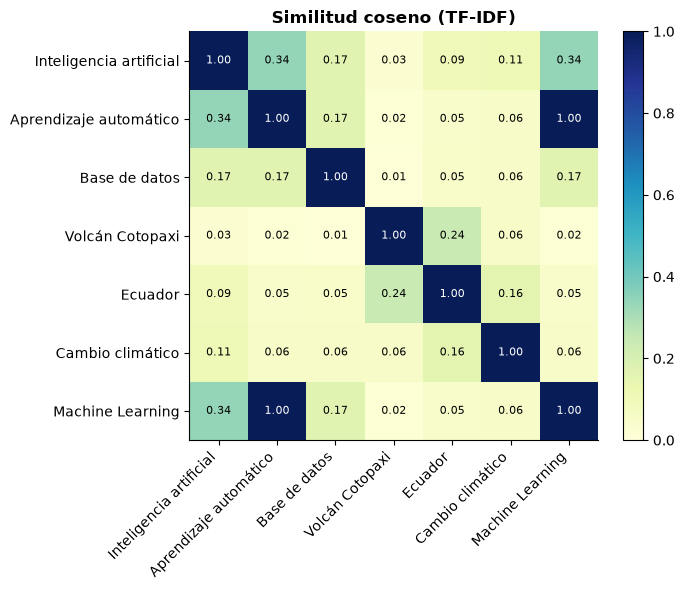

Par más parecido: «Aprendizaje automático» y «Machine Learning» → 1.00


In [12]:
similitud = tfidf_norm @ tfidf_norm.T
sim_df = pd.DataFrame(similitud, index=temas, columns=temas).round(2)
display(sim_df)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(similitud, cmap="YlGnBu", vmin=0, vmax=1)
ax.set_xticks(range(len(temas))); ax.set_xticklabels(temas, rotation=45, ha="right")
ax.set_yticks(range(len(temas))); ax.set_yticklabels(temas)
for i in range(len(temas)):
    for j in range(len(temas)):
        ax.text(j, i, f"{similitud[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if similitud[i, j] > .6 else "black")
ax.grid(False); plt.colorbar(im, fraction=.046); ax.set_title("Similitud coseno (TF-IDF)")
plt.tight_layout(); plt.show()

pares = [(temas[i], temas[j], similitud[i, j]) for i in range(len(temas)) for j in range(i + 1, len(temas))]
mejor = max(pares, key=lambda x: x[2])
print(f"Par más parecido: «{mejor[0]}» y «{mejor[1]}» → {mejor[2]:.2f}")

**Mapa de documentos en 2D** (descomposición SVD): textos con vocabulario parecido quedan cerca.

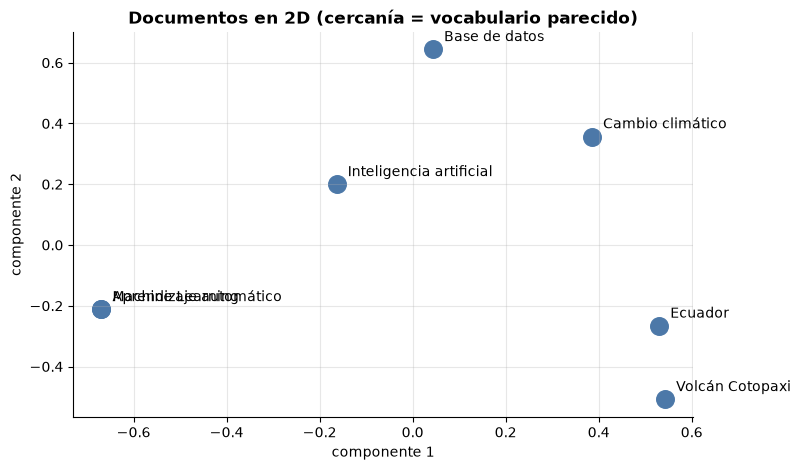

In [13]:
centrada = tfidf_norm - tfidf_norm.mean(axis=0)
U, S, Vt = np.linalg.svd(centrada, full_matrices=False)
coords = U[:, :2] * S[:2]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(coords[:, 0], coords[:, 1], s=160, color="#4C78A8")
for (x, y), t in zip(coords, temas):
    ax.annotate(t, (x, y), textcoords="offset points", xytext=(8, 6), fontsize=10)
ax.set_title("Documentos en 2D (cercanía = vocabulario parecido)")
ax.set_xlabel("componente 1"); ax.set_ylabel("componente 2"); ax.grid(alpha=.3)
plt.show()

## 5.6 De texto a variables estructuradas
Con **expresiones regulares** y estadísticas simples, cada texto se convierte en una **fila de una tabla**.

In [14]:
RE_ANIO = r"\b(?:1\d{3}|20\d{2})\b"


def caracteristicas_texto(texto):
    toks = limpiar_texto(texto, quitar_stop=False)
    anios = [int(a) for a in re.findall(RE_ANIO, texto)]
    return {
        "n_palabras": len(toks),
        "riqueza_lexica": round(len(set(toks)) / max(1, len(toks)), 3),         # palabras únicas / totales
        "long_media_palabra": round(float(np.mean([len(w) for w in toks])), 2),
        "n_anios": len(anios),
        "anio_min": min(anios) if anios else None,
        "anio_max": max(anios) if anios else None,
    }


feat_texto = pd.DataFrame.from_dict({t: caracteristicas_texto(d["texto"]) for t, d in corpus.items()}, orient="index")
display(feat_texto)

# posibles nombres propios (heurística: palabras con mayúscula inicial, ignorando el comienzo de oración)
def nombres_propios(texto, n=6):
    cand = re.findall(r"(?<![.!?]\s)(?<!^)\b[A-ZÁÉÍÓÚÑ][a-záéíóúüñ]{3,}\b", texto)
    return [w for w, _ in Counter(cand).most_common(n)]

display(pd.Series({t: ", ".join(nombres_propios(d["texto"])) for t, d in corpus.items()}, name="posibles nombres propios"))

,n_palabras,riqueza_lexica,long_media_palabra,n_anios,anio_min,anio_max
Inteligencia artificial,9013,0.355,6.95,150,1000,2035
Aprendizaje automático,2041,0.443,6.91,17,1073,2019
Base de datos,3045,0.381,6.75,3,1970,2016
Volcán Cotopaxi,744,0.602,6.49,16,1698,2015
Ecuador,12915,0.335,6.61,294,1000,2050
Cambio climático,6771,0.354,6.83,102,1002,2052
Machine Learning,2041,0.443,6.91,17,1073,2019


Inteligencia artificial    Artificial, Inteligencia, Google, John, Turing, Information
Aprendizaje automático         Learning, Machine, Aprendizaje, Markov, Redes, Software
Base de datos                             Bases, Datos, Lenguaje, Database, Base, Este
Volcán Cotopaxi            Cotopaxi, Ecuador, Andes, Tungurahua, Chimborazo, Instituto
Ecuador                           Ecuador, Guayaquil, Quito, Nacional, Estado, Función
Cambio climático                      Tierra, Cambio, Climático, Europa, Science, Niño
Machine Learning               Learning, Machine, Aprendizaje, Markov, Redes, Software
Name: posibles nombres propios, dtype: str

# 6 · Análisis de imágenes

Una imagen digital es una **matriz de números**: `alto × ancho × 3` (canales **R**ojo, **V**erde, **A**zul), con valores de 0 a 255.

| Pregunta | Característica | Cómo se calcula |
|---|---|---|
| ¿Es clara u oscura? | **brillo** | media de la imagen en escala de grises |
| ¿Tiene mucho contraste? | **contraste** | desviación estándar del gris |
| ¿De qué color es? | **color medio** | media por canal R, G, B |
| ¿Tiene mucho detalle? | **bordes** | cambio medio entre píxeles vecinos |
| ¿Se parece a otra? | **huella visual** | imagen 8×8 en blanco/negro → 64 bits |

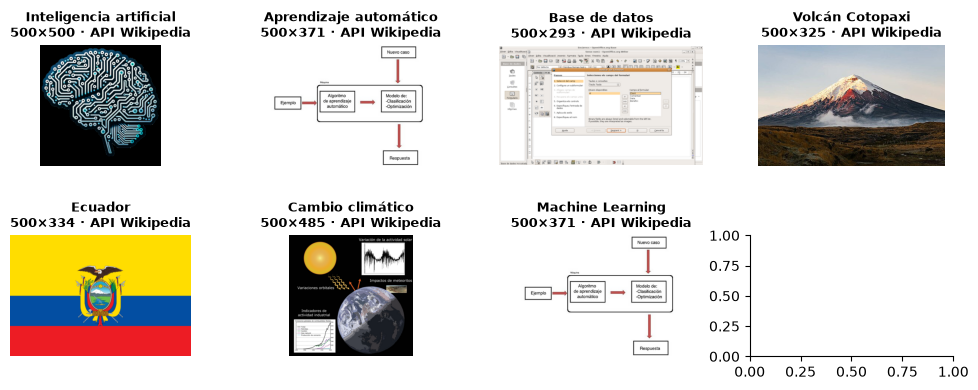

In [15]:
def imagen_sintetica(semilla, ancho=400, alto=300):
    # imagen de respaldo: degradado de color + formas + ruido (solo se usa si no hay imagen real)
    rng = np.random.default_rng(semilla)
    c1, c2 = rng.integers(20, 235, 3), rng.integers(20, 235, 3)
    t = np.linspace(0, 1, ancho)[None, :, None]
    base = (c1[None, None, :] * (1 - t) + c2[None, None, :] * t) * np.ones((alto, 1, 1))
    for _ in range(4):
        x0, y0 = int(rng.integers(0, ancho - 80)), int(rng.integers(0, alto - 60))
        base[y0:y0 + int(rng.integers(30, 60)), x0:x0 + int(rng.integers(40, 80))] = rng.integers(0, 255, 3)
    base += rng.normal(0, 6, base.shape)
    return Image.fromarray(np.clip(base, 0, 255).astype("uint8"))


imagenes, origen_img = {}, {}
for i, (tema, d) in enumerate(corpus.items()):
    try:
        if d["url_imagen"] is None:
            raise ValueError("sin imagen")
        imagenes[tema] = descargar_imagen(d["url_imagen"]); origen_img[tema] = "API Wikipedia"
    except Exception:
        imagenes[tema] = imagen_sintetica(100 + i); origen_img[tema] = "sintética (respaldo)"

fig, axes = plt.subplots(2, 4, figsize=(10, 4))
for ax, (tema, img) in zip(axes.ravel(), imagenes.items()):
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{tema}\n{img.size[0]}×{img.size[1]} · {origen_img[tema]}", fontsize=9)
plt.tight_layout(h_pad=3); plt.show()

## 6.1 La imagen como matriz
Mira los números reales de un pequeño recorte.

Forma (alto, ancho, canales): (325, 500, 3) | tipo: uint8 | rango: 0 – 255

Recorte 3×3 del canal ROJO:
[[204 204 204]
 [205 205 205]
 [206 206 206]]

Píxel (100, 100) = [R, G, B] = [204 209 212]


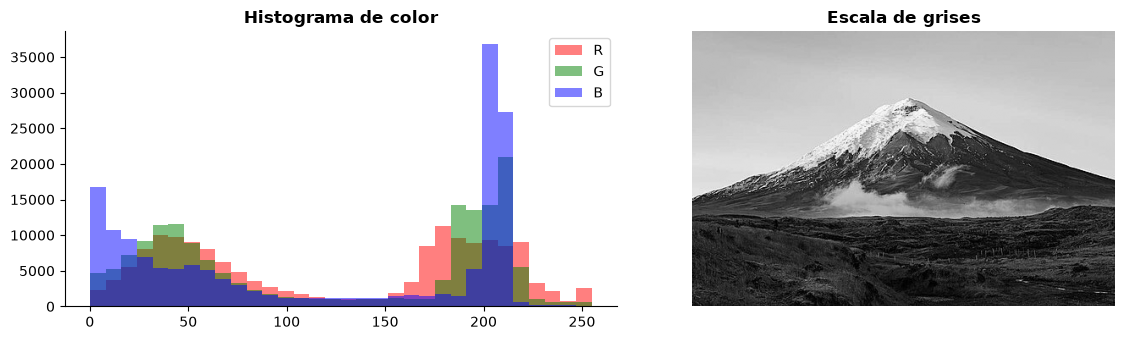

In [16]:
img0 = imagenes[TEMAS[3]]
arr0 = np.asarray(img0)
print("Forma (alto, ancho, canales):", arr0.shape, "| tipo:", arr0.dtype, "| rango:", arr0.min(), "–", arr0.max())
print("\nRecorte 3×3 del canal ROJO:")
print(arr0[100:103, 100:103, 0])
print("\nPíxel (100, 100) = [R, G, B] =", arr0[100, 100])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i, (col, nom) in enumerate([("red", "R"), ("green", "G"), ("blue", "B")]):
    ax[0].hist(arr0[..., i].ravel(), bins=32, color=col, alpha=.5, label=nom)
ax[0].set_title("Histograma de color"); ax[0].legend()
ax[1].imshow(np.asarray(img0.convert("L")), cmap="gray"); ax[1].axis("off"); ax[1].set_title("Escala de grises")
plt.tight_layout(); plt.show()

## 6.2 Características de cada imagen
Igual que con el texto: de la imagen salen **columnas numéricas**.

,ancho,alto,brillo,contraste,rojo,verde,azul,bordes,canal_dominante
Inteligencia artificial,500,500,51.1,83.1,42.0,54.3,58.9,11.95,azul
Aprendizaje automático,500,371,243.5,47.9,244.2,243.2,243.2,6.47,rojo
Base de datos,500,293,234.4,28.7,237.2,233.8,230.2,6.22,rojo
Volcán Cotopaxi,500,325,122.2,79.4,124.3,121.8,118.5,10.07,rojo
Ecuador,500,334,141.2,63.4,187.9,135.1,49.4,1.69,rojo
Cambio climático,500,485,77.7,95.5,80.1,77.4,73.0,7.05,rojo
Machine Learning,500,371,243.5,47.9,244.2,243.2,243.2,6.47,rojo


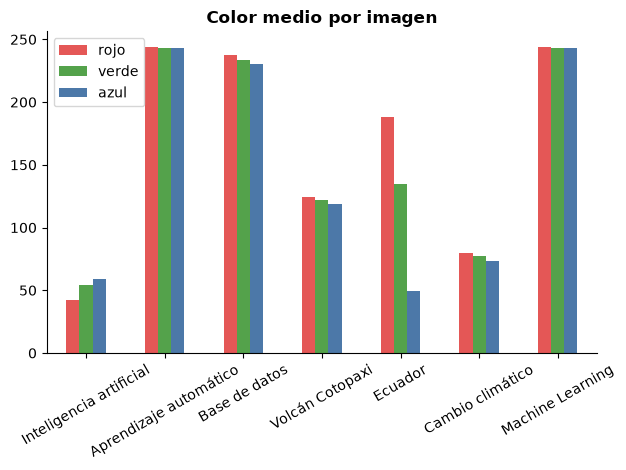

In [17]:
def caracteristicas_imagen(img):
    a = np.asarray(img).astype(float)
    gris = a @ np.array([0.299, 0.587, 0.114])
    bordes = (np.abs(np.diff(gris, axis=1)).mean() + np.abs(np.diff(gris, axis=0)).mean()) / 2
    medias = a.reshape(-1, 3).mean(axis=0)
    return {"ancho": img.size[0], "alto": img.size[1], "brillo": round(gris.mean(), 1),
            "contraste": round(gris.std(), 1), "rojo": round(medias[0], 1), "verde": round(medias[1], 1),
            "azul": round(medias[2], 1), "bordes": round(bordes, 2),
            "canal_dominante": ["rojo", "verde", "azul"][int(np.argmax(medias))]}


feat_img = pd.DataFrame.from_dict({t: caracteristicas_imagen(im) for t, im in imagenes.items()}, orient="index")
display(feat_img)

feat_img[["rojo", "verde", "azul"]].plot.bar(color=["#E45756", "#54A24B", "#4C78A8"], rot=30,
                                                            title="Color medio por imagen")
plt.tight_layout(); plt.show()

## 6.3 Huella visual (*average hash*)
Reducimos la imagen a **8×8 en grises**, marcamos cada píxel como más claro o más oscuro que el promedio y obtenemos **64 bits**. La **distancia de Hamming** (bits distintos) mide qué tan diferentes son dos imágenes.

In [18]:
def huella(img):
    g = np.asarray(img.convert("L").resize((8, 8))).astype(float)
    return (g > g.mean()).ravel()


huellas = {t: huella(im) for t, im in imagenes.items()}
dist = pd.DataFrame([[int((huellas[a] != huellas[b]).sum()) for b in temas] for a in temas], index=temas, columns=temas)
display(dist)
print("0 = huellas idénticas · 64 = totalmente opuestas")

,Inteligencia artificial,Aprendizaje automático,Base de datos,Volcán Cotopaxi,Ecuador,Cambio climático,Machine Learning
Inteligencia artificial,0,41,38,23,19,36,41
Aprendizaje automático,41,0,37,32,34,29,0
Base de datos,38,37,0,51,51,32,37
Volcán Cotopaxi,23,32,51,0,4,35,32
Ecuador,19,34,51,4,0,35,34
Cambio climático,36,29,32,35,35,0,29
Machine Learning,41,0,37,32,34,29,0


0 = huellas idénticas · 64 = totalmente opuestas


# 7 · Otros datos no estructurados y tabla final

### Audio, video y documentos (resumen conceptual)

| Dato | Cómo se vuelve estructurado | Librerías habituales |
|---|---|---|
| **Audio** | espectrograma, duración, volumen, transcripción a texto | `librosa`, `whisper` |
| **Video** | secuencia de imágenes (fotogramas) + audio | `opencv-python` |
| **PDF / escaneos** | extracción de texto (o OCR) → texto | `pdfplumber`, `pytesseract` |
| **Redes sociales** | texto + imágenes + metadatos (JSON) | APIs de cada plataforma |

### Tabla final: lo no estructurado, ya estructurado
Unimos las características de **texto** e **imagen** de cada artículo en **una sola tabla**.

In [19]:
tabla_final = feat_texto.join(feat_img.drop(columns=["ancho", "alto"]), how="left")
tabla_final.insert(0, "origen_texto", [corpus[t]["origen"] for t in tabla_final.index])
display(tabla_final)

num = tabla_final.select_dtypes("number")
print("Ahora podemos usar todas las herramientas de datos estructurados. Por ejemplo, correlación entre columnas:")
display(num.corr().round(2).loc[["n_palabras", "riqueza_lexica"], ["brillo", "contraste", "bordes"]])
print("(Con solo 6 artículos estas correlaciones son ilustrativas, no concluyentes.)")

,origen_texto,n_palabras,riqueza_lexica,long_media_palabra,n_anios,anio_min,anio_max,brillo,contraste,rojo,verde,azul,bordes,canal_dominante
Inteligencia artificial,API Wikipedia,9013,0.355,6.95,150,1000,2035,51.1,83.1,42.0,54.3,58.9,11.95,azul
Aprendizaje automático,API Wikipedia,2041,0.443,6.91,17,1073,2019,243.5,47.9,244.2,243.2,243.2,6.47,rojo
Base de datos,API Wikipedia,3045,0.381,6.75,3,1970,2016,234.4,28.7,237.2,233.8,230.2,6.22,rojo
Volcán Cotopaxi,API Wikipedia,744,0.602,6.49,16,1698,2015,122.2,79.4,124.3,121.8,118.5,10.07,rojo
Ecuador,API Wikipedia,12915,0.335,6.61,294,1000,2050,141.2,63.4,187.9,135.1,49.4,1.69,rojo
Cambio climático,API Wikipedia,6771,0.354,6.83,102,1002,2052,77.7,95.5,80.1,77.4,73.0,7.05,rojo
Machine Learning,API Wikipedia,2041,0.443,6.91,17,1073,2019,243.5,47.9,244.2,243.2,243.2,6.47,rojo


Ahora podemos usar todas las herramientas de datos estructurados. Por ejemplo, correlación entre columnas:


,brillo,contraste,bordes
n_palabras,-0.55,0.36,-0.35
riqueza_lexica,0.18,0.01,0.39


(Con solo 6 artículos estas correlaciones son ilustrativas, no concluyentes.)


# 8 · Buenas prácticas al consumir APIs

-  **Identifícate** con `User-Agent` (y un contacto).
-  **No satures** el servidor: pausas entre peticiones y **caché** local (como hicimos).
-  **Reintenta** con espera creciente si hay errores temporales (`429`, `5xx`).
-  **Valida la respuesta**: revisa `status_code`, la clave `error` y que existan los campos esperados.
-  Si una API **sí** pide clave, **nunca** la escribas en el notebook: usa variables de entorno.
-  Revisa la **licencia** y cita la fuente (aquí, Wikipedia, CC BY-SA).
-  Prepara un **plan B** (datos de respaldo) para que tu análisis no dependa 100 % de Internet.

# 9 · Ejercicios

**Reglas**
- Escribe tu código donde dice `# TU CÓDIGO AQUÍ` y deja el resultado en la variable `respuesta`.
- Ejecuta la celda de cada ejercicio para **autocorregirte**: te dirá ✅ o ❌ sin mostrarte la solución.
- Puedes usar todo lo definido en el notebook: `consultar_wikipedia`, `limpiar_texto`, `STOPWORDS`, `Counter`, `np`, `re`…
- El ejercicio 1 necesita Internet; los demás funcionan sin conexión.

In [20]:
# Datos fijos para los ejercicios (los mismos para todos)
TEXTO_EJ2 = "¡Hola, Mundo! Visita https://ejemplo.com/datos en 2025: ¡Datos NO estructurados 100% útiles!"
TEXTO_EJ3 = "Los datos no estructurados incluyen texto, imágenes y audio. El texto crece cada día; los datos de texto son los más comunes."
DOC_A = "la inteligencia artificial analiza datos"
DOC_B = "la inteligencia artificial analiza imágenes y datos"
TEXTO_EJ6 = "En 1969 nació Arpanet; en 1991 se publicó la web y en 2007 apareció el iPhone. En 2022 llegaron los chatbots masivos."

IMG_EJ = np.zeros((40, 60, 3), dtype=np.uint8)
IMG_EJ[:, :30] = [200, 40, 40]      # mitad izquierda: rojo intenso
IMG_EJ[:, 30:] = [30, 60, 220]      # mitad derecha: azul intenso
print("Datos de los ejercicios listos · IMG_EJ:", IMG_EJ.shape)

Datos de los ejercicios listos · IMG_EJ: (40, 60, 3)


In [21]:
ESPERADOS = {
 "ej2": "hola mundo visita en datos no estructurados útiles",
 "ej3": [
  [
   "texto",
   3
  ],
  [
   "datos",
   2
  ]
 ],
 "ej4": 0.894,
 "ej5": {
  "brillo": 78.56,
  "canal_dominante": "azul"
 },
 "ej6": {
  "n_anios": 4,
  "anio_min": 1969,
  "anio_max": 2022
 }
}


def _norm(x):
    return json.loads(json.dumps(x, default=lambda o: o.item() if hasattr(o, "item") else str(o)))


def _igual(a, b):
    if isinstance(b, dict):
        return isinstance(a, dict) and all(k in a and _igual(a[k], b[k]) for k in b)
    if isinstance(b, list):
        return isinstance(a, list) and len(a) == len(b) and all(_igual(x, y) for x, y in zip(a, b))
    if isinstance(b, (int, float)) and not isinstance(b, bool):
        try:
            return abs(float(a) - float(b)) <= 0.011
        except Exception:
            return False
    return str(a).strip() == str(b).strip()


def verificar(clave, resp):
    vacio = resp is None or (isinstance(resp, dict) and any(v is None for v in resp.values()))
    if vacio:
        print("✏️ Aún no hay respuesta: completa el código y la variable 'respuesta'.")
        return
    resp = _norm(resp)
    if clave == "ej1":                       # se corrige por estructura (la API cambia con el tiempo)
        try:
            ok = bool(str(resp["titulo"]).strip()) and 1 <= int(resp["n_resultados"]) <= 5
        except Exception:
            ok = False
    else:
        ok = _igual(resp, ESPERADOS[clave])
    print("✅ ¡Correcto!" if ok else "❌ Todavía no coincide. Revisa tu código y la pista del enunciado.")

## Ejercicio 1 · Comunicarse con la API  ⭐

Usa `consultar_wikipedia` para **buscar** el tema `"volcán Cotopaxi"` pidiendo un máximo de **5 resultados**.

Respuesta: el **título** del primer resultado y **cuántos** resultados llegaron.

*(Este ejercicio necesita conexión a Internet. Se corrige por estructura, no por valor, porque Wikipedia cambia con el tiempo.)*

<details><summary>💡 Pista</summary>

Parámetros: `action=query`, `list=search`, `srsearch=<tema>`, `srlimit=5`. Los resultados están en `datos["query"]["search"]` y cada uno tiene la clave `title`.

</details>

In [22]:
datos = None
titulo_usado = "Volcán Cotopaxi"

resultado = buscar_articulos(titulo_usado,n=5)
contar_resultados = len(resultado)

print("Hay un total de", contar_resultados, "resultados para el título",titulo_usado)
respuesta = {"titulo": titulo_usado, "n_resultados":contar_resultados}

verificar("ej1", respuesta)

Hay un total de 5 resultados para el título Volcán Cotopaxi
✅ ¡Correcto!


## Ejercicio 2 · Normalizar texto  ⭐⭐

Escribe la función **`normalizar(texto)`** que:

1. pase todo a **minúsculas**,
2. **elimine las URL** (`http://...` o `https://...`),
3. elimine números y signos, dejando solo letras (con tildes y ñ) y espacios,
4. **colapse** los espacios múltiples y quite los de los extremos.

Respuesta: `normalizar(TEXTO_EJ2)`.

<details><summary>💡 Pista</summary>

`re.sub(r"https?://\S+", " ", t)`, luego `re.sub(r"[^a-záéíóúüñ\s]", " ", t)` y por último `" ".join(t.split())`.

</details>

In [23]:
def normalizar(texto):
    t = texto.lower()
    t = re.sub(r"https?://\S+", " ", t)
    t = re.sub(r"[^a-záéíóúüñ\s]", " ", t)
    t = " ".join(t.split())
    return t

respuesta = normalizar(TEXTO_EJ2)
print("Resultado:", respuesta)

verificar("ej2", respuesta)


Resultado: hola mundo visita en datos no estructurados útiles
✅ ¡Correcto!


## Ejercicio 3 · Frecuencia de palabras  ⭐⭐

Con la función `limpiar_texto` del notebook (tokeniza y elimina *stopwords*), obtén las **2 palabras más frecuentes** de `TEXTO_EJ3`.

Respuesta: lista de pares `(palabra, frecuencia)`, de mayor a menor.

<details><summary>💡 Pista</summary>

`Counter(tokens).most_common(2)`.

</details>

In [28]:
tokens = limpiar_texto(TEXTO_EJ3)

respuesta = Counter(tokens).most_common(2)

print("Tokens limpios:", tokens)
print("Respuesta:", respuesta)

verificar("ej3", respuesta)


Tokens limpios: ['datos', 'estructurados', 'incluyen', 'texto', 'imágenes', 'audio', 'texto', 'crece', 'día', 'datos', 'texto', 'comunes']
Respuesta: [('texto', 3), ('datos', 2)]
✅ ¡Correcto!


## Ejercicio 4 · Similitud entre textos  ⭐⭐⭐

Calcula la **similitud coseno** entre `DOC_A` y `DOC_B` usando la **bolsa de palabras** (conteo de cada palabra, tras `limpiar_texto`).

> similitud = (A · B) / (‖A‖ · ‖B‖)

Respuesta: un número entre 0 y 1, redondeado a 3 decimales.

<details><summary>💡 Pista</summary>

Arma el vocabulario con la unión de los tokens de ambos textos, crea un vector de conteos para cada uno con `Counter`, y usa `np.dot` y `np.linalg.norm`.

</details>

In [29]:
tokens_a = limpiar_texto(DOC_A)
tokens_b = limpiar_texto(DOC_B)

vocabulario = sorted(list(set(tokens_a) | set(tokens_b)))

conteo_a = Counter(tokens_a)
conteo_b = Counter(tokens_b)

vector_a = np.array([conteo_a[palabra] for palabra in vocabulario], dtype=float)
vector_b = np.array([conteo_b[palabra] for palabra in vocabulario], dtype=float)

producto_punto = np.dot(vector_a, vector_b)
norma_a = np.linalg.norm(vector_a)
norma_b = np.linalg.norm(vector_b)

similitud = producto_punto / (norma_a * norma_b)
respuesta = round(float(similitud), 3)

print("Vocabulario:", vocabulario)
print("Vector A:", vector_a)
print("Vector B:", vector_b)
print("Similitud:", respuesta)

verificar("ej4", respuesta)


Vocabulario: ['analiza', 'artificial', 'datos', 'imágenes', 'inteligencia']
Vector A: [1. 1. 1. 0. 1.]
Vector B: [1. 1. 1. 1. 1.]
Similitud: 0.894
✅ ¡Correcto!


## Ejercicio 5 · Una imagen es una matriz  ⭐⭐⭐

`IMG_EJ` es una imagen de 40 × 60 píxeles (matriz `alto × ancho × 3` con canales R, G, B).

1. Calcula el **brillo medio** en escala de grises: `0.299·R + 0.587·G + 0.114·B`, promediado sobre todos los píxeles.
2. Indica el **canal con mayor valor medio** (`"rojo"`, `"verde"` o `"azul"`).

Respuesta: `{"brillo": <2 decimales>, "canal_dominante": <texto>}`.

<details><summary>💡 Pista</summary>

`gris = IMG_EJ @ np.array([0.299, 0.587, 0.114])` (convierte a float) y `IMG_EJ.reshape(-1, 3).mean(axis=0)` para las medias por canal.

</details>

In [30]:
img_float = IMG_EJ.astype(float)

pesos_gris = np.array([0.299, 0.587, 0.114])
gris = img_float @ pesos_gris

brillo = round(float(gris.mean()), 2)

medias_canales = img_float.reshape(-1, 3).mean(axis=0)

nombres_canales = ["rojo", "verde", "azul"]
canal_dominante = nombres_canales[int(np.argmax(medias_canales))]

respuesta = {
    "brillo": brillo,
    "canal_dominante": canal_dominante
}

print("Brillo medio:", brillo)
print("Medias canales [R, G, B]:", medias_canales)
print("Respuesta:", respuesta)

verificar("ej5", respuesta)


Brillo medio: 78.56
Medias canales [R, G, B]: [115.  50. 130.]
Respuesta: {'brillo': 78.56, 'canal_dominante': 'azul'}
✅ ¡Correcto!


## Ejercicio 6 · De texto a variables estructuradas  ⭐⭐⭐

Con una **expresión regular**, extrae de `TEXTO_EJ6` todos los **años** (números de 4 dígitos entre 1000 y 2099).

Respuesta: `{"n_anios": <cuántos>, "anio_min": <el menor>, "anio_max": <el mayor>}` (números enteros).

<details><summary>💡 Pista</summary>

`re.findall(r"\b(?:1\d{3}|20\d{2})\b", texto)` devuelve texto; conviértelo con `int`.

</details>

In [31]:
patron_anios = r"\b(?:1\d{3}|20\d{2})\b"
anios_encontrados = re.findall(patron_anios, TEXTO_EJ6)

anios = [int(a) for a in anios_encontrados]

respuesta = {
    "n_anios": len(anios),
    "anio_min": min(anios),
    "anio_max": max(anios)
}

print("Años encontrados:", anios)
print("Respuesta:", respuesta)

verificar("ej6", respuesta)


Años encontrados: [1969, 1991, 2007, 2022]
Respuesta: {'n_anios': 4, 'anio_min': 1969, 'anio_max': 2022}
✅ ¡Correcto!


# ✅ Cierre

**Lo esencial**
- Los datos **no estructurados** (texto, imagen, audio, video) no tienen esquema fijo: hay que **extraer características** para analizarlos.
- Una **API** permite obtenerlos de forma programática; Wikipedia ofrece una **sin credenciales**.
- El flujo es siempre: **obtener → preprocesar → representar → analizar → comunicar**.
- Texto → *tokens*, frecuencias, TF-IDF, similitud. Imagen → matriz de píxeles, color, brillo, contraste, huella.
- Al final, lo no estructurado termina en una **tabla estructurada** lista para el análisis tradicional.

**Para seguir practicando:** cambia `TEMAS` (o `IDIOMA = "en"`), añade tus propios artículos y observa cómo cambian la similitud y las palabras distintivas.